# Data Preprocessing (Structural + Site)

Fetch structural brain measures (FreeSurfer) from ABIDE, clean them, add the acquisition site as one-hot columns, and save them ready for training.


**About ABIDE** 

The Autism Brain Imaging Data Exchange (ABIDE) dataset provides previously collected resting state functional magnetic resonance imaging datasets from 539 individuals with ASD and 573 typical controls for the purpose of data sharing in the broader scientific community. 

Besides the fMRI data, the ABIDE Preprocessed project provides the FreeSurfer (v5.1) outputs of the structural MRI scans, such as the volume of each subcortical region and the total gray matter volume.

In [1]:
# Import
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch.utils.data import TensorDataset
import os
import json
import urllib.request

## Phenotypic Data

The phenotypic data metadata was retrieved from http://fcon_1000.projects.nitrc.org/indi/abide/abide_I.html, in the "ABIDE I Downloads" section, specifically the *Phenotypic Data Legend* download

Selecting the healthy controls (`DX_GROUP == 2`) that passed the anatomical quality control, and extracting `FILE_ID`, `AGE_AT_SCAN` and `SEX`.

In [2]:
# ABIDE base url
abide_url = "https://fcp-indi.s3.amazonaws.com/data/Projects/ABIDE_Initiative"

# Phenotypic data (download only if not already in the data folder)
pheno_path = "../data/ABIDE_pcp/Phenotypic_V1_0b_preprocessed1.csv"
if not os.path.exists(pheno_path):
    os.makedirs(os.path.dirname(pheno_path), exist_ok=True)
    urllib.request.urlretrieve(f"{abide_url}/Phenotypic_V1_0b_preprocessed1.csv", pheno_path)

df = pd.read_csv(pheno_path)
print(f"Total subjects: {len(df)}")
print(df.columns)
df.head(3)

Total subjects: 1112
Index(['Unnamed: 0.1', 'Unnamed: 0', 'SUB_ID', 'X', 'subject', 'SITE_ID',
       'FILE_ID', 'DX_GROUP', 'DSM_IV_TR', 'AGE_AT_SCAN',
       ...
       'qc_notes_rater_1', 'qc_anat_rater_2', 'qc_anat_notes_rater_2',
       'qc_func_rater_2', 'qc_func_notes_rater_2', 'qc_anat_rater_3',
       'qc_anat_notes_rater_3', 'qc_func_rater_3', 'qc_func_notes_rater_3',
       'SUB_IN_SMP'],
      dtype='object', length=106)


,Unnamed: 0.1,Unnamed: 0,SUB_ID,X,subject,SITE_ID,FILE_ID,DX_GROUP,DSM_IV_TR,AGE_AT_SCAN,...,qc_notes_rater_1,qc_anat_rater_2,qc_anat_notes_rater_2,qc_func_rater_2,qc_func_notes_rater_2,qc_anat_rater_3,qc_anat_notes_rater_3,qc_func_rater_3,qc_func_notes_rater_3,SUB_IN_SMP
0,0,1,50002,1,50002,PITT,no_filename,1,1,16.77,...,NaN,OK,NaN,fail,ic-parietal-cerebellum,OK,NaN,fail,ERROR #24,1
1,1,2,50003,2,50003,PITT,Pitt_0050003,1,1,24.45,...,NaN,OK,NaN,OK,NaN,OK,NaN,OK,NaN,1
2,2,3,50004,3,50004,PITT,Pitt_0050004,1,1,19.09,...,NaN,OK,NaN,OK,NaN,OK,NaN,OK,NaN,1


In [3]:
# Filter for Healthy Controls (DX_GROUP == 2) with available data
df = df[(df['DX_GROUP'] == 2) & (df['FILE_ID'] != 'no_filename')].copy()

# Anatomical quality control (same raters as Nilearn, anatomical only)
df = df[(df['qc_rater_1'] == 'OK') &
        (df['qc_anat_rater_2'].isin(['OK', 'maybe'])) &
        (df['qc_anat_rater_3'] == 'OK')].copy()

# Select ID, Site, Age and Sex
df = df[['FILE_ID', 'SITE_ID', 'AGE_AT_SCAN', 'SEX']].copy()

# Map SEX (ABIDE uses 1=Male, 2=Female) to 0 and 1
df['SEX'] = df['SEX'].map({1: 0, 2: 1})

print(f"Healthy controls: {len(df)}")
df.head()

Healthy controls: 477


,FILE_ID,SITE_ID,AGE_AT_SCAN,SEX
26,Pitt_0050030,PITT,25.12,0
27,Pitt_0050031,PITT,12.92,0
28,Pitt_0050032,PITT,19.80,0
29,Pitt_0050033,PITT,12.15,0
30,Pitt_0050034,PITT,14.77,0


## FreeSurfer Data

For each subject, the file `aseg.stats` contains the volume (mm³) of each subcortical region (e.g. hippocampus), and whole brain measures (e.g. total gray matter volume, intracranial volume).

Files are downloaded from `{abide_url}/Outputs/freesurfer/5.1/<FILE_ID>/stats/aseg.stats` into `../data/freesurfer`.

In [4]:
# Download aseg.stats for each subject (skip the ones already downloaded)
fs_dir = "../data/freesurfer"
os.makedirs(fs_dir, exist_ok=True)

missing = []
for file_id in df['FILE_ID']:
    local_path = f"{fs_dir}/{file_id}_aseg.stats"
    if os.path.exists(local_path):
        continue
    try:
        urllib.request.urlretrieve(f"{abide_url}/Outputs/freesurfer/5.1/{file_id}/stats/aseg.stats", local_path)
    except Exception:
        missing.append(file_id)

print(f"Files in {fs_dir}: {len(os.listdir(fs_dir))}")
print(f"Subjects without aseg.stats: {len(missing)}")

Files in ../data/freesurfer: 477
Subjects without aseg.stats: 0


## Target Extraction

From each `aseg.stats` file, extracting:
* `TotalGrayVol`: total gray matter volume (mm³), the target variable.
* `IntraCranialVol`: intracranial volume (head size), to normalize volumes later if needed.
* `Left-Hippocampus` and `Right-Hippocampus` volumes (mm³), as a possible second target.

Whole brain measures are in the header lines starting with `# Measure`, and the regional volumes are in the table (column `Volume_mm3`).

In [5]:
# Example: first subject's file
example_path = f"{fs_dir}/{df['FILE_ID'].iloc[0]}_aseg.stats"
with open(example_path) as f:
    lines = f.readlines()

# Whole brain measures
for line in lines:
    if line.startswith('# Measure'):
        print(line.strip())

# Table header and the hippocampus rows
for line in lines:
    if 'ColHeaders' in line or 'Hippocampus' in line:
        print(line.strip())

# Measure lhCortex, lhCortexVol, Left hemisphere cortical gray matter volume, 256834.428000, mm^3
# Measure rhCortex, rhCortexVol, Right hemisphere cortical gray matter volume, 258579.686475, mm^3
# Measure Cortex, CortexVol, Total cortical gray matter volume, 515414.114475, mm^3
# Measure lhCorticalWhiteMatter, lhCorticalWhiteMatterVol, Left hemisphere cortical white matter volume, 268936.531250, mm^3
# Measure rhCorticalWhiteMatter, rhCorticalWhiteMatterVol, Right hemisphere cortical white matter volume, 270330.062500, mm^3
# Measure CorticalWhiteMatter, CorticalWhiteMatterVol, Total cortical white matter volume, 539266.593750, mm^3
# Measure SubCortGray, SubCortGrayVol, Subcortical gray matter volume, 191167.000000, mm^3
# Measure TotalGray, TotalGrayVol, Total gray matter volume, 706581.114475, mm^3
# Measure SupraTentorial, SupraTentorialVol, Supratentorial volume, 1162485.913079, mm^3
# Measure IntraCranialVol, ICV, Intracranial Volume, 1157527.387605, mm^3
# ColHeaders  Index Se

In [6]:
def read_aseg(path):
    """
    Read the volumes of interest from a FreeSurfer aseg.stats file.

    path: path to the aseg.stats file
    Returns: dictionary with TotalGrayVol, IntraCranialVol, Left-Hippocampus, Right-Hippocampus (mm³)
    """
    values = {}
    with open(path) as f:
        for line in f:
            if line.startswith('# Measure'):
                # e.g. "# Measure TotalGray, TotalGrayVol, Total gray matter volume, 728816.39, mm^3"
                parts = line.split(', ')
                if parts[1] in ['TotalGrayVol', 'ICV']:
                    name = 'IntraCranialVol' if parts[1] == 'ICV' else parts[1]
                    values[name] = float(parts[3])
            elif not line.startswith('#'):
                # e.g. "12  17  3287  3287.0  Left-Hippocampus ..."
                parts = line.split()
                if parts[4] in ['Left-Hippocampus', 'Right-Hippocampus']:
                    values[parts[4]] = float(parts[3])
    return values

# Loop through on the healthy files
volumes = [read_aseg(f"{fs_dir}/{file_id}_aseg.stats") for file_id in df['FILE_ID']]
volumes = pd.DataFrame(volumes, index=df.index)
volumes['Hippocampus'] = volumes['Left-Hippocampus'] + volumes['Right-Hippocampus']

In [7]:
# Add the volume columns and drop NaNs
df = pd.concat([df, volumes], axis=1)
if df.isna().sum().sum() != 0:
    print("NA records", df.isna().sum())
    df = df.dropna()
else:
    pass

print(f"Healthy controls: {len(df)}")
df.head()

Healthy controls: 477


,FILE_ID,SITE_ID,AGE_AT_SCAN,SEX,TotalGrayVol,IntraCranialVol,Left-Hippocampus,Right-Hippocampus,Hippocampus
26,Pitt_0050030,PITT,25.12,0,706581.114475,1.157527e+06,3982.0,4061.0,8043.0
27,Pitt_0050031,PITT,12.92,0,783889.187268,1.208583e+06,4235.0,4477.0,8712.0
28,Pitt_0050032,PITT,19.80,0,730058.146235,1.206391e+06,4475.0,4598.0,9073.0
29,Pitt_0050033,PITT,12.15,0,720818.859215,1.059904e+06,4445.0,4379.0,8824.0
30,Pitt_0050034,PITT,14.77,0,729693.739442,1.094946e+06,4074.0,4394.0,8468.0


**Site**

Brain volumes differ a lot between sites (scanner and acquisition differences). The site is added as one-hot columns (`site_<SITE_ID>`, 1 if the subject was scanned at that site, 0 otherwise), so the model can learn the site differences.

In [8]:
# One-hot encoding of the site
site_dummies = pd.get_dummies(df['SITE_ID'], prefix='site', dtype=int)
df = pd.concat([df, site_dummies], axis=1)
site_cols = list(site_dummies.columns)

print(f"Number of sites: {len(site_cols)}")
print(df['SITE_ID'].value_counts())

Number of sites: 20
SITE_ID
NYU         99
UM_1        52
MAX_MUN     27
UCLA_1      27
PITT        26
TRINITY     25
USM         25
UM_2        21
KKI         21
SDSU        19
YALE        19
LEUVEN_2    17
CALTECH     15
SBL         15
OLIN        14
LEUVEN_1    14
STANFORD    13
OHSU        13
UCLA_2      10
CMU          5
Name: count, dtype: int64


**Age effect**

Checking that the target changes with age before training the model.

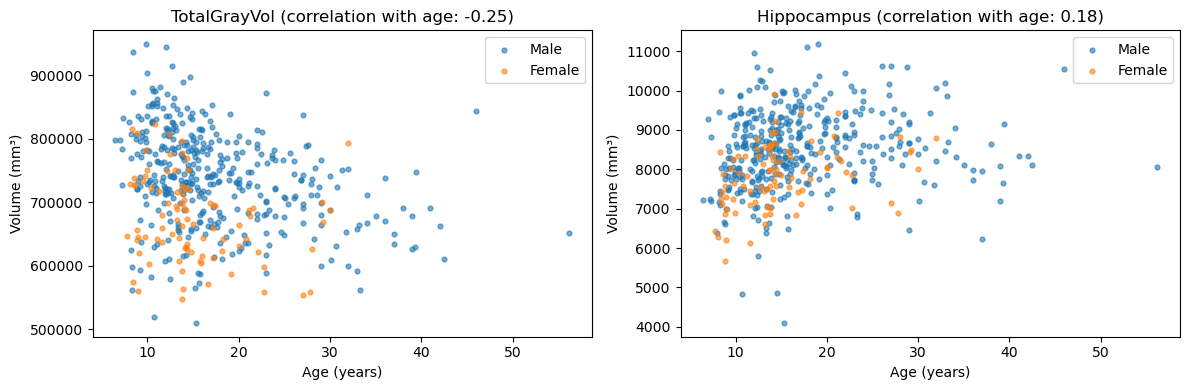

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['TotalGrayVol', 'Hippocampus']):
    for sex, label in [(0, 'Male'), (1, 'Female')]:
        subset = df[df['SEX'] == sex]
        ax.scatter(subset['AGE_AT_SCAN'], subset[col], s=12, alpha=0.6, label=label)
    corr = np.corrcoef(df['AGE_AT_SCAN'], df[col])[0, 1]
    ax.set_title(f"{col} (correlation with age: {corr:.2f})")
    ax.set_xlabel('Age (years)')
    ax.set_ylabel('Volume (mm³)')
    ax.legend()
plt.tight_layout()
plt.show()

**Feature Scaling**

Z-score scaling of `AGE_AT_SCAN` and `TotalGrayVol`. The scaling parameters are saved to transform predictions back to original units.

In [10]:
# Mean and std
age_mean = float(df['AGE_AT_SCAN'].mean())
age_std = float(df['AGE_AT_SCAN'].std())
vol_mean = float(df['TotalGrayVol'].mean())
vol_std = float(df['TotalGrayVol'].std())

# Scaled columns
df['Age_scaled'] = (df['AGE_AT_SCAN'] - age_mean) / age_std
df['TotalGrayVol_scaled'] = (df['TotalGrayVol'] - vol_mean) / vol_std

# Save scaling parameters
scaling_params = {'age_mean': age_mean, 'age_std': age_std, 'vol_mean': vol_mean, 'vol_std': vol_std}
os.makedirs("../data/processed", exist_ok=True)
with open("../data/processed/scaling_params_structural_site.json", "w") as f:
    json.dump(scaling_params, f, indent=4)

print(scaling_params)
df.head()

{'age_mean': 16.95909895178197, 'age_std': 7.32014240993593, 'vol_mean': 726986.6218631573, 'vol_std': 77565.06628857981}


,FILE_ID,SITE_ID,AGE_AT_SCAN,SEX,TotalGrayVol,IntraCranialVol,Left-Hippocampus,Right-Hippocampus,Hippocampus,site_CALTECH,...,site_STANFORD,site_TRINITY,site_UCLA_1,site_UCLA_2,site_UM_1,site_UM_2,site_USM,site_YALE,Age_scaled,TotalGrayVol_scaled
26,Pitt_0050030,PITT,25.12,0,706581.114475,1.157527e+06,3982.0,4061.0,8043.0,0,...,0,0,0,0,0,0,0,0,1.114856,-0.263076
27,Pitt_0050031,PITT,12.92,0,783889.187268,1.208583e+06,4235.0,4477.0,8712.0,0,...,0,0,0,0,0,0,0,0,-0.551779,0.733611
28,Pitt_0050032,PITT,19.80,0,730058.146235,1.206391e+06,4475.0,4598.0,9073.0,0,...,0,0,0,0,0,0,0,0,0.388094,0.039599
29,Pitt_0050033,PITT,12.15,0,720818.859215,1.059904e+06,4445.0,4379.0,8824.0,0,...,0,0,0,0,0,0,0,0,-0.656968,-0.079517
30,Pitt_0050034,PITT,14.77,0,729693.739442,1.094946e+06,4074.0,4394.0,8468.0,0,...,0,0,0,0,0,0,0,0,-0.299051,0.034901


# PyTorch Dataset

Checking that the inputs (`Age_scaled`, `SEX` and the site columns) and target (`TotalGrayVol_scaled`) can be converted into a PyTorch `TensorDataset`.

In [11]:
# Inputs and target as tensors
X = torch.tensor(df[['Age_scaled', 'SEX'] + site_cols].values, dtype=torch.float32)
y = torch.tensor(df['TotalGrayVol_scaled'].values, dtype=torch.float32).unsqueeze(1)

# call dataset
dataset = TensorDataset(X, y)
print(f"Total samples in dataset: {len(dataset)}")
print("The first person (record): ")
print(f"[Age,Sex,Sites]: {dataset[0][0]}") # For sex, 0 = MALE, and 1 = FEMALE
print(f"[TotalGrayVol]: {dataset[0][1]}")

Total samples in dataset: 477
The first person (record): 
[Age,Sex,Sites]: tensor([1.1149, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
        0.0000, 0.0000, 0.0000, 0.0000])
[TotalGrayVol]: tensor([-0.2631])


In [12]:
output_path = "../data/processed/abide_structural_site_cleaned.csv"
df.to_csv(output_path, index=False)
print(f"Dataset saved at: {output_path}")

Dataset saved at: ../data/processed/abide_structural_site_cleaned.csv
